Titanic Survival Prediction Model
#loading the training data from csv and testing it aganist the test csv file

In [13]:
import pandas as pd
import numpy as np

df=pd.read_csv("titanic_train.csv")
df.info()
df.head(3)


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [14]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [15]:
#here after identifying the missing values we came to know that the column cabin has 687 missing values which is mostly 72% of data is missing
#by filing this cabin column doesnt help our model and may lead to noise data so we are dropping the column cabin
#missing values in a column age is trying to fill with the mean

df=df.drop(columns=["PassengerId","Cabin","Name","Ticket","Fare"])
df.head(3)


,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked
0,0,3,male,22.0,1,0,S
1,1,1,female,38.0,1,0,C
2,1,3,female,26.0,0,0,S


In [22]:
df["Age"]=df["Age"].fillna(df["Age"].mean())
df["Embarked"]=df["Embarked"].fillna(df["Embarked"].mode()[0])
df.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Embarked    0
dtype: int64

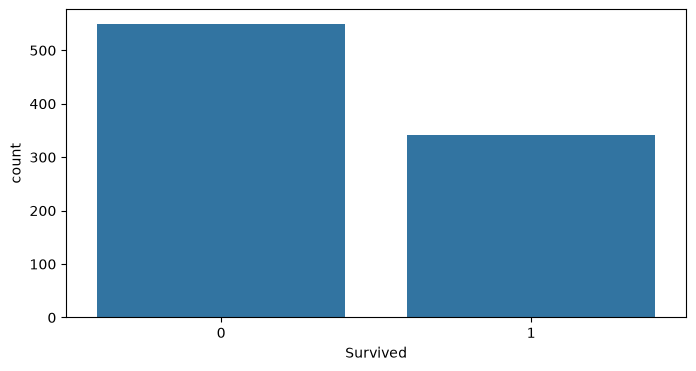

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,4))
sns.countplot(data=df,x="Survived")
plt.show()

<Axes: xlabel='Pclass', ylabel='Count'>

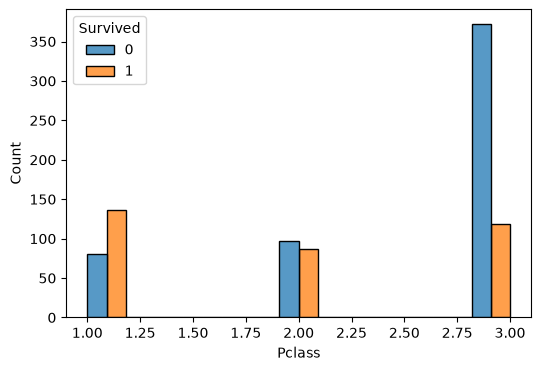

In [33]:
plt.figure(figsize=(6,4))
sns.histplot(data=df,x="Pclass",hue="Survived",multiple="dodge")

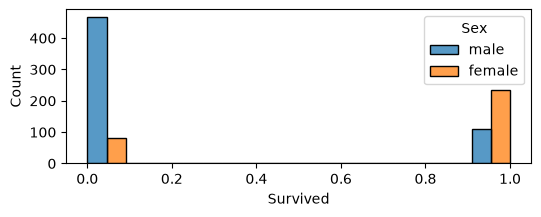

In [36]:
plt.figure(figsize=(6,2))
sns.histplot(data=df,x="Survived",hue="Sex",multiple="dodge")
plt.show()

In [59]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["Sex"]=le.fit_transform(df["Sex"])
df["Embarked"]=le.fit_transform(df["Embarked"])
df.head(3)

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked
0,0,3,1,22.0,1,0,2
1,1,1,0,38.0,1,0,0
2,1,3,0,26.0,0,0,2


In [60]:
x=df.drop(columns=["Survived"])
y=df["Survived"]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,shuffle=True)


In [65]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
def model_train(x_train,y_train,x_test,y_test,model):
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    print("Accuracy Score:",accuracy_score(y_test,y_pred))
    print("Confusion Matrix:\n",confusion_matrix(y_test,y_pred))
    print("Classification Report:\n",classification_report(y_test,y_pred))
    return y_pred

In [67]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model_train(x_train,y_train,x_test,y_test,model)

Accuracy Score: 0.8100558659217877
Confusion Matrix:
 [[90 15]
 [19 55]]
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 1])

In [68]:
#testing the model with a new data that outside of the training or testing data
test_df = pd.DataFrame({
    "Pclass": [1, 3, 1, 3, 2, 3, 1, 2],
    "Sex": ["female", "male", "male", "female", "male", "male", "female", "female"],
    "Age": [29.0, 24.0, 5.0, np.nan, 41.0, 19.0, np.nan, 33.0],
    "SibSp": [0, 0, 1, 1, 0, 2, 1, 0],
    "Parch": [0, 0, 2, 0, 1, 0, 0, 1],
    "Fare": [83.1583, 8.0500, 39.0000, 15.2458, 26.0000, 7.8958, 110.8833, np.nan],
    "Embarked": ["C", "S", "S", "C", "S", "S", "C", "Q"],
    "Survived": [1, 0, 1, 1, 0, 0, 1, 1],
})
test_df["Age"] = test_df["Age"].fillna(test_df["Age"].mean())
test_df=test_df.drop(columns=["Fare"])
test_df["Sex"]=le.fit_transform(test_df["Sex"])
test_df["Embarked"]=le.fit_transform(test_df["Embarked"])
sx_test = test_df.drop(columns=["Survived"])
sy_test = test_df["Survived"]

In [69]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model_train(x_train,y_train,sx_test,sy_test,model)

Accuracy Score: 1.0
Confusion Matrix:
 [[3 0]
 [0 5]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         5

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



array([1, 0, 1, 1, 0, 0, 1, 1])